In [1]:
import os
import glob
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import layers, models, Input, mixed_precision
from sklearn.model_selection import train_test_split
import cv2
import keras
print("library loaded successfully")
print("*"*100)

I0000 00:00:1780927586.647905   13021 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


library loaded successfully
****************************************************************************************************


In [2]:
IMG_SIZE = 256  # Standardized input resolution for both phases
BATCH_SIZE = 4 # Batch size
EPOCHS_PHASE1 = 5  # Semantic Segmentation Focus, for Segmentation 
EPOCHS_PHASE2 = 10   # Segmentation-Based Classification Focus for classification Polyp and Non-Polyp

In [3]:
# Directory and Artifact Paths
DATA_PATH = '/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2'
POSITIVE_DIR = os.path.join(DATA_PATH, 'imagesAll_positive') # For Polyp classification
NEGATIVE_DIR = os.path.join(DATA_PATH, 'sequenceData/negativeOnly')  # For non polyp classification
MODEL_SAVE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras"

In [4]:
mixed_precision.set_global_policy('mixed_float16')

In [5]:
def augment(img, mask):
    """Applies shape-preserving geometric and radiometric transformations."""
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_left_right(img)
        mask = tf.image.flip_left_right(mask)
    if tf.random.uniform(()) > 0.5:
        img = tf.image.flip_up_down(img)
        mask = tf.image.flip_up_down(mask)
    
    img = tf.image.random_brightness(img, max_delta=0.15)
    img = tf.image.random_contrast(img, lower=0.85, upper=1.15)
    img = tf.clip_by_value(img, 0.0, 1.0)
    
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img, mask

In [6]:
import random

def process_path_segmentation(img_path, mask_path):
    """
    Advanced Preprocessing Wrapper for Dataset B.
    Applies CLAHE, Median Blur, Mild Sharpening, and Coarse Dropout.
    """
    def _read_and_process(img_p, mask_p):
        img_p_str = img_p.numpy().decode('utf-8') if hasattr(img_p, 'numpy') else img_p.decode('utf-8')
        mask_p_str = mask_p.numpy().decode('utf-8') if hasattr(mask_p, 'numpy') else mask_p.decode('utf-8')
        img = cv2.imread(img_p_str)
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
        mask = cv2.imread(mask_p_str, cv2.IMREAD_GRAYSCALE)
        mask = cv2.resize(mask, (IMG_SIZE, IMG_SIZE))
        # ─── STEP 1: CONTRAST ENHANCEMENT (CLAHE) ───
        lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
        l_channel, a_channel, b_channel = cv2.split(lab)
        clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
        cl = clahe.apply(l_channel)
        limg = cv2.merge((cl, a_channel, b_channel))
        enhanced_img = cv2.cvtColor(limg, cv2.COLOR_LAB2RGB)
        median_blur = cv2.medianBlur(enhanced_img, 3) 
        # ─── STEP 3: MILD SHARPENING ───
        sharpened = cv2.addWeighted(enhanced_img, 1.5, median_blur, -0.5, 0)
        """ 
        # Coarse Dropout
        if random.random() < 0.5:
            block_size = 32 
            x = random.randint(0, IMG_SIZE - block_size)
            y = random.randint(0, IMG_SIZE - block_size)
            sharpened[y:y+block_size, x:x+block_size, :] = 0  
            mask[y:y+block_size, x:x+block_size] = 0         
        """
        # ─── STEP 4: NORMALIZATION ───
        normalized_img = sharpened / 255.0
        normalized_mask = mask / 255.0
        normalized_mask = np.where(normalized_mask > 0.5, 1.0, 0.0)
        
        normalized_mask = np.expand_dims(normalized_mask, axis=-1)
        
        return normalized_img.astype(np.float32), normalized_mask.astype(np.float32)

    [img_tensor, mask_tensor] = tf.py_function(
        _read_and_process, 
        [img_path, mask_path], 
        [tf.float32, tf.float32]
    )
    img_tensor.set_shape([IMG_SIZE, IMG_SIZE, 3])
    mask_tensor.set_shape([IMG_SIZE, IMG_SIZE, 1])
    return img_tensor, mask_tensor

In [7]:
def process_path_classification(img_path, label):
    """Preprocesses input tensors and categorical targets for Dataset A."""
    img = tf.io.read_file(img_path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, [IMG_SIZE, IMG_SIZE])
    img = tf.cast(img, tf.float32) / 255.0
    img.set_shape([IMG_SIZE, IMG_SIZE, 3])
    return img, label

In [8]:
def load_segmentation_paths(base_path):
    """Extracts paired image and mask absolute paths from multi-center repositories."""
    all_images, all_masks = [], []
    for i in range(1, 7):
        center_id = f"C{i}"
        img_dir = os.path.join(base_path, f"data_{center_id}", f"images_{center_id}")
        mask_dir = os.path.join(base_path, f"data_{center_id}", f"masks_{center_id}")
        if os.path.exists(img_dir) and os.path.exists(mask_dir):
            img_paths = (glob.glob(os.path.join(img_dir, "*.jpg")) + glob.glob(os.path.join(img_dir, "*.JPG")) +
                         glob.glob(os.path.join(img_dir, "*.png")) + glob.glob(os.path.join(img_dir, "*.jpeg")))
            for img_p in img_paths:
                filename = os.path.basename(img_p)
                name_without_ext, ext = os.path.splitext(filename)
                expected_mask_name = f"{name_without_ext}_mask{ext}"
                mask_p = os.path.join(mask_dir, expected_mask_name)
                if os.path.exists(mask_p):
                    all_images.append(img_p)
                    all_masks.append(mask_p)
    return all_images, all_masks

In [9]:
def load_classification_paths():
    """Compiles absolute paths for global positive and artifact-heavy negative sequences."""
    valid_exts = ('*.png', '*.jpg', '*.jpeg', '*.bmp', '*.tif', '*.PNG', '*.JPG', '*.JPEG')
    pos_files, neg_files = [], []
    for ext in valid_exts:
        pos_files.extend(glob.glob(os.path.join(POSITIVE_DIR, "**", ext), recursive=True))
    for i in range(1, 14):
        target_folder = os.path.join(NEGATIVE_DIR, f"seq{i}_neg")
        if os.path.exists(target_folder):
            for ext in valid_exts:
                neg_files.extend(glob.glob(os.path.join(target_folder, "**", ext), recursive=True))
    pos_files = [f for f in pos_files if os.path.isfile(f)]
    neg_files = [f for f in neg_files if os.path.isfile(f)]
    
    file_paths = pos_files + neg_files
    labels = [1.0] * len(pos_files) + [0.0] * len(neg_files)
    return np.array(file_paths), np.array(labels, dtype=np.float32)

In [10]:
def se_block(input_tensor, ratio=16):
    """Channel-wise Squeeze-and-Excitation Attention Layer."""
    channels = input_tensor.shape[-1]
    squeeze = layers.GlobalAveragePooling2D()(input_tensor)
    excitation = layers.Dense(channels // ratio, activation='relu', use_bias=False)(squeeze)
    excitation = layers.Dense(channels, activation='sigmoid', use_bias=False)(excitation)
    excitation = layers.Reshape((1, 1, channels))(excitation)
    return layers.multiply([input_tensor, excitation])

In [11]:
def depthwise_seperable_conv_block(x, filters, dropout_rate=0.0, name_prefix=""):
    """Multi-Scale Parallel Kernels (3x3, 5x5, 7x7, 1x1) with Depthwise Separable Convolutions."""
    f4 = filters // 4
    b3 = layers.SeparableConv2D(f4, 3, padding='same', use_bias=False, name=f"{name_prefix}_3x3")(x)
    b3 = layers.BatchNormalization()(b3); b3 = layers.Activation('relu')(b3)
    
    b5 = layers.SeparableConv2D(f4, 5, padding='same', use_bias=False, name=f"{name_prefix}_5x5")(x)
    b5 = layers.BatchNormalization()(b5); b5 = layers.Activation('relu')(b5)
    
    b7 = layers.SeparableConv2D(f4, 7, padding='same', use_bias=False, name=f"{name_prefix}_7x7")(x)
    b7 = layers.BatchNormalization()(b7); b7 = layers.Activation('relu')(b7)
    
    b1 = layers.SeparableConv2D(f4, 1, padding='same', use_bias=False, name=f"{name_prefix}_1x1")(x)
    b1 = layers.BatchNormalization()(b1); b1 = layers.Activation('relu')(b1)
    
    merged = layers.Concatenate(name=f"{name_prefix}_concat")([b3, b5, b7, b1])
    x_se = se_block(merged, ratio=16) 
    # Feed-forward Network Integration
    if x.shape[-1] == filters:
        x_se = layers.add([x, x_se], name=f"{name_prefix}_residual")
    if dropout_rate > 0:
        x_se = layers.SpatialDropout2D(dropout_rate, name=f"{name_prefix}_dropout")(x_se)
    return x_se

In [12]:
@tf.keras.utils.register_keras_serializable()
class KerasPCCLayer(layers.Layer):
    """Natively computes spatial Pearson Correlation Coefficients within the network graph."""
    def __init__(self, **kwargs):
        super(KerasPCCLayer, self).__init__(**kwargs)

    def call(self, inputs):
        # We used epsilon sothat standard deviation value cannot be zero, otherwise code will crash
        epsilon = 1e-8
        # finds the average standard deviaiton
        mean = tf.reduce_mean(inputs, axis=-1, keepdims=True)
        std = tf.math.reduce_std(inputs, axis=-1, keepdims=True) + epsilon
        # data normalization or (Z-Score)
        norm_inputs = (inputs - mean) / std
        pcc_matrix = tf.matmul(tf.expand_dims(norm_inputs, -1), tf.expand_dims(norm_inputs, 1))
        return layers.Flatten()(pcc_matrix)

In [13]:
def build_unified_segmentation_based_model(input_shape=(256, 256, 3)):
    """
    Constructs a dual-headed multi-task Y-Net architecture.
    Shares a deeply regularized, multi-scale latent space to simultaneously
    perform semantic image segmentation and unified scene classification.
    Integrated with Deep Supervision along the decoder pathway for SOTA convergence.
    """
    # [Input Layer]: Defines the input tensor shape holding the raw 3-channel RGB medical images.
    inputs = Input(shape=input_shape, name="shared_input_image")

    # ── Shared Custom Multi-Scale Encoder ─────────────────────────────────────
    # [Enc Block 1]: Processes raw input into 32 multi-scale feature channels. Output dim: (256, 256, 32)
    c1 = depthwise_seperable_conv_block(inputs, 32, name_prefix="enc_c1")
    # [Max Pooling 1]: Downsamples spatial dimensions by a factor of 2. Dim: (128, 128, 32)
    p1 = layers.MaxPooling2D(2, name="enc_p1")(c1)

    # [Enc Block 2]: Extracts deeper geometric abstractions into 64 semantic channels. Output dim: (128, 128, 64)
    c2 = depthwise_seperable_conv_block(p1, 64, name_prefix="enc_c2")
    # [Max Pooling 2]: Downsamples spatial dimensions further. Dim: (64, 64, 64)
    p2 = layers.MaxPooling2D(2, name="enc_p2")(c2)

    # [Enc Block 3]: Scales representation to 128 channels. Dim: (64, 64, 128)
    c3 = depthwise_seperable_conv_block(p2, 128, dropout_rate=0.1, name_prefix="enc_c3")
    # [Max Pooling 3]: Reduces resolution further. Dim: (32, 32, 128)
    p3 = layers.MaxPooling2D(2, name="enc_p3")(c3)

    # [Enc Block 4]: Captures high-level contextual abstracts across 256 channels. Dim: (32, 32, 256)
    c4 = depthwise_seperable_conv_block(p3, 256, dropout_rate=0.2, name_prefix="enc_c4")
    # [Max Pooling 4]: Compresses spatial grid to its lowest native encoder resolution. Dim: (16, 16, 256)
    p4 = layers.MaxPooling2D(2, name="enc_p4")(c4)
    
    # ── Shared Representation Latent Bottleneck ───────────────────────────────
    # [Shared Bottleneck]: Maps the compressed grid into a highly dense 512-channel latent feature space. Dim: (16, 16, 512)
    b = depthwise_seperable_conv_block(p4, 512, dropout_rate=0.3, name_prefix="shared_bottleneck")

    # ── Output Branch A: Semantic Segmentation Decoder with Deep Supervision ──
    # [Upsampling 4]: Uses learned transpose convolution filters to upscale the latent grid. Dim: (32, 32, 256)
    u4 = layers.Conv2DTranspose(256, 2, strides=2, padding='same', name="dec_u4")(b)
    # [Skip Connection 4]: Concatenates low-level encoder features (c4). Total channels: 256 + 256 = 512
    u4 = layers.concatenate([u4, c4], name="dec_concat_4")
    # [Dec Block 5]: Regularizes concatenated representation back to 256 optimized features. Dim: (32, 32, 256)
    c5 = depthwise_seperable_conv_block(u4, 256, dropout_rate=0.2, name_prefix="dec_c5")

    # Deep Supervision process integration
    ds1 = layers.Conv2D(1, 1, padding='same', name='ds1_conv')(c5)
    ds1 = layers.UpSampling2D(size=(8, 8), interpolation='bilinear', dtype='float32', name='ds1_output')(ds1)

    # [Upsampling 3]: Expands spatial dimensions. Dim: (64, 64, 128)
    u3 = layers.Conv2DTranspose(128, 2, strides=2, padding='same', name="dec_u3")(c5)
    # [Skip Connection 3]: Merges encoder's mid-level details (c3). Total channels: 128 + 128 = 256
    u3 = layers.concatenate([u3, c3], name="dec_concat_3")
    # [Dec Block 6]: Consolidates features. Dim: (64, 64, 128)
    c6 = depthwise_seperable_conv_block(u3, 128, dropout_rate=0.1, name_prefix="dec_c6")

    ds2 = layers.Conv2D(1, 1, padding='same', name='ds2_conv')(c6)
    ds2 = layers.UpSampling2D(size=(4, 4), interpolation='bilinear', dtype='float32', name='ds2_output')(ds2)

    # [Upsampling 2]: Output dim: (128, 128, 64)
    u2 = layers.Conv2DTranspose(64, 2, strides=2, padding='same', name="dec_u2")(c6)
    # [Skip Connection 2]: Re-introduces high-resolution textures from c2. Total channels: 64 + 64 = 128
    u2 = layers.concatenate([u2, c2], name="dec_concat_2")
    # [Dec Block 7]: Harmonizes maps into 64 channels. Dim: (128, 128, 64)
    c7 = depthwise_seperable_conv_block(u2, 64, name_prefix="dec_c7")


    ds3 = layers.Conv2D(1, 1, padding='same', name='ds3_conv')(c7)
    ds3 = layers.UpSampling2D(size=(2, 2), interpolation='bilinear', dtype='float32', name='ds3_output')(ds3)

    # [Upsampling 1]: Restores feature maps back to the original input spatial size. Output dim: (256, 256, 32)
    u1 = layers.Conv2DTranspose(32, 2, strides=2, padding='same', name="dec_u1")(c7)
    # [Skip Connection 1]: Concat-links raw spatial coordinates directly from c1. Total channels: 32 + 32 = 64
    u1 = layers.concatenate([u1, c1], name="dec_concat_1")
    # [Dec Block 8]: Refines final decoded features. Dim: (256, 256, 32)
    c8 = depthwise_seperable_conv_block(u1, 32, name_prefix="dec_c8")

    # [Main Segmentation Mask Output]: ওরিজিনাল ফাইনাল আউটপুট
    segmentation_output = layers.Conv2D(1, 1, activation='sigmoid', dtype='float32', name='seg_output')(c8)

    # ── Output Branch B: Segmentation-Guided Classification Head ──────────────
    # [Classification CNN]: Performs light 3x3 depthwise separable convolution. Dim: (16, 16, 32)
    pd_cnn = layers.SeparableConv2D(32, (3, 3), padding='same', activation='relu', name="clf_pd_cnn")(b)
    # [Max Pooling]: Downsamples classification maps spatially. Output dim: (8, 8, 32)
    p_pool = layers.MaxPooling2D((2, 2), name="clf_maxpool")(pd_cnn)
    
    # [Global Average Pooling (GAP)]: Collapses spatial dimensions into a single vector.
    flat_features = layers.GlobalAveragePooling2D(name="clf_gap")(p_pool)
    # [Keras PCC Layer]: Computes Linear statistical dependency.
    pcc_features = KerasPCCLayer(name="clf_pcc_layer")(flat_features)
    # [Z-Score Normalization]: Stabilizes dense convergence.
    standardized = layers.BatchNormalization(name="clf_zscore_bn")(pcc_features)
    
    # [Fully Connected Dense]: Learns non-linear correlation.
    d1 = layers.Dense(64, activation='relu', name="clf_dense1")(standardized)
    # [Dropout]: Prevent Overfitting
    d1 = layers.Dropout(0.3, name="clf_dropout")(d1)
    # [Classification Score Output]: Yields global disease probability.
    classification_output = layers.Dense(1, activation='sigmoid', dtype='float32', name='clf_output')(d1)

    # ── [Model Compilation Graph Finalization] ────────────────────────────────
    return models.Model(
        inputs=inputs, 
        outputs=[segmentation_output, ds1, ds2, ds3, classification_output], 
        name="Thesis_DeepSupervised_YNet"
    )

In [14]:
@keras.saving.register_keras_serializable()
def dice_coef(y_true, y_pred, smooth=1.0):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)


In [15]:
def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)
def bce_dice_loss(y_true, y_pred):
    bce = tf.reduce_mean(tf.keras.losses.binary_crossentropy(y_true, y_pred))
    return bce + dice_loss(y_true, y_pred)

In [16]:
def focal_tversky_loss(y_true, y_pred, alpha=0.7, beta=0.3, gamma=0.75):
    """
    Focal Tversky Loss for imbalanced medical image segmentation.
    alpha: controls penalty for False Negatives (FN) -> keeping it higher (0.7) focuses on small polyps.
    beta: controls penalty for False Positives (FP).
    """
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    # Calculate True Positives, False Negatives, and False Positives
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    
    # Tversky Index
    smooth = 1e-6
    tversky_index = (tp + smooth) / (tp + alpha * fn + beta * fp + smooth)
    
    # Focal Tversky Loss
    return tf.math.pow((1.0 - tversky_index), gamma)

In [17]:
@keras.saving.register_keras_serializable()
def iou_metric(y_true, y_pred):
    y_true_f = tf.cast(y_true, tf.float32)
    y_pred_f = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + 1.0) / (union + 1.0)

In [18]:
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator

In [20]:
@keras.saving.register_keras_serializable()
def f2_segmentation(y_true, y_pred):
    y_true_f = tf.cast(tf.reshape(y_true, [-1]), tf.float32)
    y_pred_f = tf.cast(tf.reshape(y_pred, [-1]), tf.float32)
    
    y_pred_f = tf.cast(y_pred_f > 0.5, tf.float32)
    
    tp = tf.reduce_sum(y_true_f * y_pred_f)
    fp = tf.reduce_sum((1.0 - y_true_f) * y_pred_f)
    fn = tf.reduce_sum(y_true_f * (1.0 - y_pred_f))

    numerator = 5.0 * tp + 1e-7
    denominator = 5.0 * tp + 4.0 * fn + fp + 1e-7
    
    return numerator / denominator

In [21]:
# # Initialize allocation strategy for physical compute hardware by scanning for available GPU units.
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus: tf.config.experimental.set_memory_growth(gpu, True)
        print("✓ Tensor Graph Allocation Locked over available GPU nodes.")
    except RuntimeError as e: print(e)

# 1. PARSE PIPELINE DIRECTORIES
print("\n[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...")
seg_imgs, seg_masks = load_segmentation_paths(DATA_PATH)
s_train_x, s_val_x, s_train_y, s_val_y = train_test_split(seg_imgs, seg_masks, test_size=0.2, random_state=42)

print("[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...")
clf_imgs, clf_labels = load_classification_paths()
indices = np.arange(len(clf_imgs))
np.random.seed(42); np.random.shuffle(indices)
clf_imgs, clf_labels = clf_imgs[indices], clf_labels[indices]
c_split = int(0.8 * len(clf_imgs))

# 2. GENERATE HIGH-THROUGHPUT ITERATORS
print("\n⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...")

# --- Segmentation Datasets ---
train_seg_ds = tf.data.Dataset.from_tensor_slices((s_train_x, s_train_y)) \
    .shuffle(len(s_train_x)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .map(augment, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_seg_ds = tf.data.Dataset.from_tensor_slices((s_val_x, s_val_y)) \
    .map(process_path_segmentation, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)


train_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[:c_split], clf_labels[:c_split])) \
    .shuffle(1024) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

val_clf_ds = tf.data.Dataset.from_tensor_slices((clf_imgs[c_split:], clf_labels[c_split:])) \
    .map(process_path_classification, num_parallel_calls=tf.data.AUTOTUNE) \
    .batch(BATCH_SIZE) \
    .prefetch(tf.data.AUTOTUNE)

# 3. GRAPH INSTANTIATION
print("\n🏗️ Compiling Dual-Head Computation Topology...")
model = build_unified_segmentation_based_model()

# 🌟 STAGE 1: SEMANTIC SEGMENTATION MAXIMIZATION (Dataset B Only)
print("\n=======================================================")
print("[PHASE 1] Optimizing Localization Ensembles & Structural Layers")
print("=======================================================")

# Freeze classification branch entirely to avoid uninitialized variable gradients
for layer in model.layers:
    if "clf_" in layer.name:
        layer.trainable = False
    else:
        layer.trainable = True

model.compile(
    optimizer=mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=1e-3)),
    loss=[focal_tversky_loss, None],
    #metrics=[[dice_coef, iou_metric, 'accuracy'], []]
    metrics = {
        'seg_output': [
            'accuracy',                                      
            tf.keras.metrics.Recall(name='recall'),          
            tnr_metric,
            dice_coef,
            iou_metric,
            f2_segmentation
        ]
    }
)




# ── FIXED CALLBACKS FOR PHASE 1 ──────────────────────────────────────────
phase1_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(MODEL_SAVE_PATH, monitor='val_seg_output_dice_coef', save_best_only=True, mode='max', verbose=1),
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-4, verbose=1)
]

# PHASE 1 Training started ...
history_p1 = model.fit(train_seg_ds, validation_data=val_seg_ds, epochs=EPOCHS_PHASE1, callbacks=phase1_callbacks, verbose=1)
print("[PHASE 1 COMPLETE] Spatial boundaries locked successfully.")








✓ Tensor Graph Allocation Locked over available GPU nodes.

[Data Ingestion] Parsing Multi-Center Localization Data (Dataset B)...
[Data Ingestion] Parsing Balanced Sequence Arrays (Dataset A)...

⚡ Initializing Multi-Threaded High-Throughput Iterators via AUTOTUNE...

🏗️ Compiling Dual-Head Computation Topology...

[PHASE 1] Optimizing Localization Ensembles & Structural Layers
Epoch 1/5


/mnt/c/development/Thesis/PotatoDiseaseClassification-CNN/linux-venv/lib/python3.12/site-packages/keras/src/optimizers/base_optimizer.py:862: UserWarning: Gradients do not exist for variables ['ds1_conv/kernel', 'ds1_conv/bias', 'ds2_conv/kernel', 'ds2_conv/bias', 'ds3_conv/kernel', 'ds3_conv/bias'] when minimizing the loss. If using `model.compile()`, did you forget to provide a `loss` argument?
  warnings.warn(
I0000 00:00:1780928211.273391   20846 service.cc:153] XLA service 0x7bc72409ef50 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1780928211.273462   20846 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1780928212.317706   20846 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1780928223.037941   20846 cuda_dnn.cc:461] Loaded cu

307/307 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.7551 - seg_output_accuracy: 0.6482 - seg_output_dice_coef: 0.2302 - seg_output_f2_segmentation: 0.4201 - seg_output_iou_metric: 0.1568 - seg_output_recall: 0.8038 - seg_output_tnr_metric: 0.5988

I0000 00:00:1780928465.503444   20845 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_4', 56 bytes spill stores, 56 bytes spill loads




Epoch 1: val_seg_output_dice_coef improved from None to 0.20318, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras
307/307 ━━━━━━━━━━━━━━━━━━━━ 289s 127ms/step - loss: 0.7087 - seg_output_accuracy: 0.7134 - seg_output_dice_coef: 0.2816 - seg_output_f2_segmentation: 0.4587 - seg_output_iou_metric: 0.1873 - seg_output_recall: 0.7755 - seg_output_tnr_metric: 0.6823 - val_loss: 0.8468 - val_seg_output_accuracy: 0.9181 - val_seg_output_dice_coef: 0.2032 - val_seg_output_f2_segmentation: 0.1828 - val_seg_output_iou_metric: 0.1342 - val_seg_output_recall: 0.1474 - val_seg_output_tnr_metric: 0.9552 - learning_rate: 0.0010
Epoch 2/5
306/307 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - loss: 0.6520 - seg_output_accuracy: 0.8089 - seg_output_dice_coef: 0

In [30]:
# =======================================================
# STAGE 2: CLASSIFICATION FINE-TUNING (Sub-Model Extraction)
# =======================================================
print("\n =======================================================")
print(" [PHASE 2] Initializing Classification Head over Locked Feature Embeddings")
print(" =======================================================")

# ১. মূল মডেল রিলোড করা
base_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects={
    'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef, 
    'iou_metric': iou_metric, 'bce_dice_loss': bce_dice_loss,
    'focal_tversky_loss': focal_tversky_loss
})

# ২. লেয়ার ফ্রিজ করা
for layer in base_model.layers:
    if "clf_" in layer.name:
        layer.trainable = True  
    else:
        layer.trainable = False 


model = tf.keras.Model(inputs=base_model.input, outputs=base_model.get_layer('clf_output').output)

model.compile(
    optimizer=mixed_precision.LossScaleOptimizer(tf.keras.optimizers.Adam(learning_rate=1e-4)),
    loss='binary_crossentropy',
    metrics=['accuracy',tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Precision(name='precision'),
        tf.keras.metrics.Recall(name='recall')]
)

phase2_callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        MODEL_SAVE_PATH, 
        monitor='val_accuracy', 
        save_best_only=True, 
        mode='max', 
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', 
        patience=25, 
        restore_best_weights=True, 
        mode='max', 
        verbose=1
    )
]


print("🚀 Training Sub-Model. Displaying clean 1-Output Classification Metrics...")
history_p2 = model.fit(
    train_clf_ds, 
    validation_data=val_clf_ds, 
    epochs=EPOCHS_PHASE2, 
    callbacks=phase2_callbacks, 
    verbose=1
)

print(f"🏆 [TRAINING COMPLETE] Sub-Model training finished. Weights updated.")


 [PHASE 2] Initializing Classification Head over Locked Feature Embeddings
🚀 Training Sub-Model. Displaying clean 1-Output Classification Metrics...
Epoch 1/10


I0000 00:00:1780934195.447529   20845 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_304728__.147
I0000 00:00:1780934201.944340   20845 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_5', 56 bytes spill stores, 56 bytes spill loads



1257/1257 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7798 - auc: 0.8609 - loss: 0.4468 - precision: 0.8245 - recall: 0.8088

I0000 00:00:1780934237.299940   20846 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1', 56 bytes spill stores, 56 bytes spill loads




Epoch 1: val_accuracy improved from None to 0.89181, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras

Epoch 1: finished saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras
1257/1257 ━━━━━━━━━━━━━━━━━━━━ 67s 39ms/step - accuracy: 0.7811 - auc: 0.8618 - loss: 0.4485 - precision: 0.8247 - recall: 0.8066 - val_accuracy: 0.8918 - val_auc: 0.9551 - val_loss: 0.2750 - val_precision: 0.9811 - val_recall: 0.8340
Epoch 2/10
1257/1257 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.7668 - auc: 0.8593 - loss: 0.4476 - precision: 0.8115 - recall: 0.7996
Epoch 2: val_accuracy improved from 0.89181 to 0.89340, saving model to /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras

Epoch 2: finished saving model to /mnt/c/development/Thesis/PolypS

In [44]:

# =======================================================
# STAGE 2: ELM INTEGRATION (Robust Dimension Fixed)
# =======================================================
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso

print("\n =======================================================")
print(" [STAGE 2] ELM INTEGRATION (PCC -> Standardization -> L1 + Pseudo-Inverse)")
print(" =======================================================")

# ১. মডেল লোড করা
print(f"🔄 Fetching peak localization weights: {MODEL_SAVE_PATH}")
base_model = tf.keras.models.load_model(MODEL_SAVE_PATH, custom_objects={
    'KerasPCCLayer': KerasPCCLayer, 'dice_coef': dice_coef, 
    'iou_metric': iou_metric, 'bce_dice_loss': bce_dice_loss,
    'focal_tversky_loss': focal_tversky_loss
})

# ২. ফিচার এক্সট্রাকশন মডেল তৈরি ('clf_output' লেয়ার থেকে সরাসরি)
feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=base_model.get_layer('clf_output').output)

# ৩. ফিচার এবং লেবেল এক্সট্রাক্ট করার গ্যারান্টিড ফাংশন
def extract_features_and_labels(dataset):
    all_features = []
    all_labels = []
    for images, labels in dataset:
        feats = feature_extractor(images, training=False)
        
        # যদি মাল্টি-আউটপুট লেবেল টাপল/লিস্ট হয়, শেষ ইনডেক্স ৪ নিচ্ছি
        if isinstance(labels, (list, tuple)):
            lbls = labels[-1]
        else:
            lbls = labels
            
        all_features.append(feats.numpy())
        all_labels.append(lbls.numpy())
        
    return np.concatenate(all_features, axis=0), np.concatenate(all_labels, axis=0)

print("⏳ Extracting feature embeddings from Dataset...")
X_train_raw, y_train = extract_features_and_labels(train_clf_ds)
X_val_raw, y_val = extract_features_and_labels(val_clf_ds)

# 🛠️ ফোর্স ফ্ল্যাটেনিং (২-ডি ম্যাট্রিক্স নিশ্চিত করা: [Samples, Features])
X_train_flat = X_train_raw.reshape(X_train_raw.shape[0], -1)
X_val_flat = X_val_raw.reshape(X_val_raw.shape[0], -1)

# যদি লেবেল ওয়ান-হট আকারে থাকে, তবে সেটিকে ১-ডি বাইনারি (0 বা 1) ভেক্টরে রূপান্তর
if len(y_train.shape) > 1 and y_train.shape[1] > 1:
    y_train = np.argmax(y_train, axis=1)
    y_val = np.argmax(y_val, axis=1)
elif len(y_train.shape) > 1:
    y_train = y_train.squeeze()
    y_val = y_val.squeeze()

print(f"   Shape Verified -> Train Features: {X_train_flat.shape}, Train Labels: {y_train.shape}")

# ৪. STEP A: Pearson Correlation Coefficient (PCC) Feature Selection (বুলেটপ্রুফ মেথড)
print("📉 Step A: Executing Pearson Correlation Coefficient (PCC)...")
# প্রতিটা ফিচারের সাথে টার্গেট লেবেলের (y_train) কোরিলেশন বের করা (সবচেয়ে স্টেবল রিসার্চ মেথড)
pcc_scores = []
for col in range(X_train_flat.shape[1]):
    feat_col = X_train_flat[:, col]
    if np.std(feat_col) == 0: # ভ্যারিয়েন্স শূন্য হলে কোরিলেশন ০
        pcc_scores.append(0)
    else:
        corr = np.corrcoef(feat_col, y_train)[0, 1]
        pcc_scores.append(abs(corr) if not np.isnan(corr) else 0)

pcc_scores = np.array(pcc_scores)

# থ্রেশহোল্ড সেট করা: যে ফিচারগুলোর টার্গেটের সাথে কোরিলেশন অন্তত ০.১, সেগুলোকে রাখা হবে
selected_by_pcc = np.where(pcc_scores > 0.05)[0]

# যদি খুব বেশি ফিচার বাদ পড়ে যায়, তবে টপ ৫০টি ফিচার ব্যাকআপ হিসেবে রাখা
if len(selected_by_pcc) < 5:
    selected_by_pcc = np.argsort(pcc_scores)[-50:]

X_train_pcc = X_train_flat[:, selected_by_pcc]
X_val_pcc = X_val_flat[:, selected_by_pcc]
print(f"   PCC Selected Core Diagnostic Features: {X_train_pcc.shape[1]}")

# ৫. STEP B: Standardization
print("⚖️ Step B: Applying Robust Standardization...")
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_pcc)
X_val_scaled = scaler.transform(X_val_pcc)

# ৬. STEP C: L1-Regularization (Lasso) + Pseudo-Inverse ELM Engine
print("🧠 Step C: Training Extreme Learning Machine with L1 + Pseudo-Inverse...")

l1_penalty = Lasso(alpha=0.001, max_iter=2000, random_state=42)
l1_penalty.fit(X_train_scaled, y_train)

active_features = np.where(l1_penalty.coef_ != 0)[0]
print(f"✂️ L1-Regularization Pruned down to {len(active_features)} ultimate features!")

if len(active_features) == 0:
    active_features = np.argsort(np.abs(l1_penalty.coef_))[-10:]

X_train_elm = X_train_scaled[:, active_features]
X_val_elm = X_val_scaled[:, active_features]

# Moore-Penrose Pseudo-Inverse সলিউশন
H_pseudo_inverse = np.linalg.pinv(X_train_elm)
W_optimal = np.dot(H_pseudo_inverse, y_train)
print("🎯 ELM Optimal Weights computed instantly via Matrix Inversion!")

# 🎯 ৭. চূড়ান্ত ইভালুয়েশন মেথড
def evaluate_elm(X, y_true, set_name="Validation"):
    raw_preds = np.dot(X, W_optimal)
    probs = 1 / (1 + np.exp(-np.clip(raw_preds, -20, 20))) # ওভারফ্লো প্রোটেকশন
    preds = (probs > 0.5).astype(int)
    
    accuracy = np.mean(preds == y_true)
    
    tp = np.sum((preds == 1) & (y_true == 1))
    fp = np.sum((preds == 1) & (y_true == 0))
    fn = np.sum((preds == 0) & (y_true == 1))
    
    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    
    print(f"\n📈 [{set_name} Results Summary]:")
    print(f"   Accuracy  : {accuracy*100:.2f}%")
    print(f"   Precision : {precision*100:.2f}%")
    print(f"   Recall    : {recall*100:.2f}%")
    print(f"   F1-Score  : {f1*100:.2f}%")

evaluate_elm(X_train_elm, y_train, set_name="Training")
evaluate_elm(X_val_elm, y_val, set_name="Validation")




 [STAGE 2] ELM INTEGRATION (PCC -> Standardization -> L1 + Pseudo-Inverse)
🔄 Fetching peak localization weights: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/unified_net/thesis_v3_sequential_8_6_02_ds_xai_.keras
⏳ Extracting feature embeddings from Dataset...
   Shape Verified -> Train Features: (5025, 1), Train Labels: (5025,)
📉 Step A: Executing Pearson Correlation Coefficient (PCC)...
   PCC Selected Core Diagnostic Features: 1
⚖️ Step B: Applying Robust Standardization...
🧠 Step C: Training Extreme Learning Machine with L1 + Pseudo-Inverse...
✂️ L1-Regularization Pruned down to 1 ultimate features!
🎯 ELM Optimal Weights computed instantly via Matrix Inversion!

📈 [Training Results Summary]:
   Accuracy  : 87.48%
   Precision : 99.01%
   Recall    : 79.93%
   F1-Score  : 88.46%

📈 [Validation Results Summary]:
   Accuracy  : 87.99%
   Precision : 98.38%
   Recall    : 81.12%
   F1-Score  : 88.92%


ModuleNotFoundError: No module named 'seaborn'

In [46]:
!pip install seaborn

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 1.3 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 294.9/294.9 kB 3.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.9/10.9 MB 5.1 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


In [49]:

# =======================================================
# 📊 BONUS: t-SNE VISUALIZATION ON ULTIMATE ELM FEATURES
# =======================================================
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

print("\n" + "="*55)
print(" 📉 Launching t-SNE Dim-Reduction on Final Selected ELM Features...")


# ১. ইএলএম-এর চূড়ান্ত সিলেকশন করা ফিচারগুলোর ওপর t-SNE রান করা
# X_val_elm এবং y_val আপনার মূল কোড থেকে সরাসরি এখানে ইনপুট হচ্ছে
tsne = TSNE(n_components=2, perplexity=30, n_iter=1000, random_state=42)
X_val_tsne = tsne.fit_transform(X_val_elm)

# ২. প্লট করার জন্য সুন্দর করে একটি ডাটাফ্রেম সাজানো
tsne_df = pd.DataFrame({
    't-SNE Component 1': X_val_tsne[:, 0],
    't-SNE Component 2': X_val_tsne[:, 1],
    'Diagnosis': ['Polyp' if label == 1 else 'Non-Polyp' for label in y_val.flatten()]
})

# ৩. হাই-রেজোলিউশন পাবলিকেশন কোয়ালিটি গ্রাফ সেটআপ (300 DPI)
plt.figure(figsize=(10, 8), dpi=300)
sns.set_theme(style="whitegrid")

# থিসিসের জন্য স্ট্যান্ডার্ড এবং ক্লিন কালার প্যালেট
custom_palette = {"Polyp": "#e63946", "Non-Polyp": "#2a9d8f"} # লাল = ইনফেক্টেড/পলিপ, টিল = ভালো

sns.scatterplot(
    x='t-SNE Component 1', 
    y='t-SNE Component 2',
    hue='Diagnosis',
    palette=custom_palette,
    data=tsne_df,
    alpha=0.85,
    s=65,             # ডটের সাইজ স্পষ্ট রাখার জন্য
    edgecolor='w',
    linewidth=0.6
)

# ৪. টাইটেল এবং এক্সিস লেবেলিং (থিসিস স্ট্যান্ডার্ড)
plt.title('t-SNE Feature Space Mapping after PCC + L1 Feature Selection', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('t-SNE Dimension 1', fontsize=11, fontweight='bold')
plt.ylabel('t-SNE Dimension 2', fontsize=11, fontweight='bold')
plt.legend(title='🔬 Tissue Class', title_fontsize='11', loc='best', frameon=True, shadow=True)

plt.tight_layout()

# সরাসরি আপনার থিসিস চ্যাপ্টারের জন্য ইমেজ ফাইল আকারে সেভ করে রাখার কমান্ড
# plt.savefig('elm_pruned_features_tsne.png', dpi=300, bbox_inches='tight')

plt.show()
print("🏆 [SUCCESS] t-SNE Map rendered for Selected Diagnostic Features!")


 📉 Launching t-SNE Dim-Reduction on Final Selected ELM Features...


TypeError: TSNE.__init__() got an unexpected keyword argument 'n_iter'

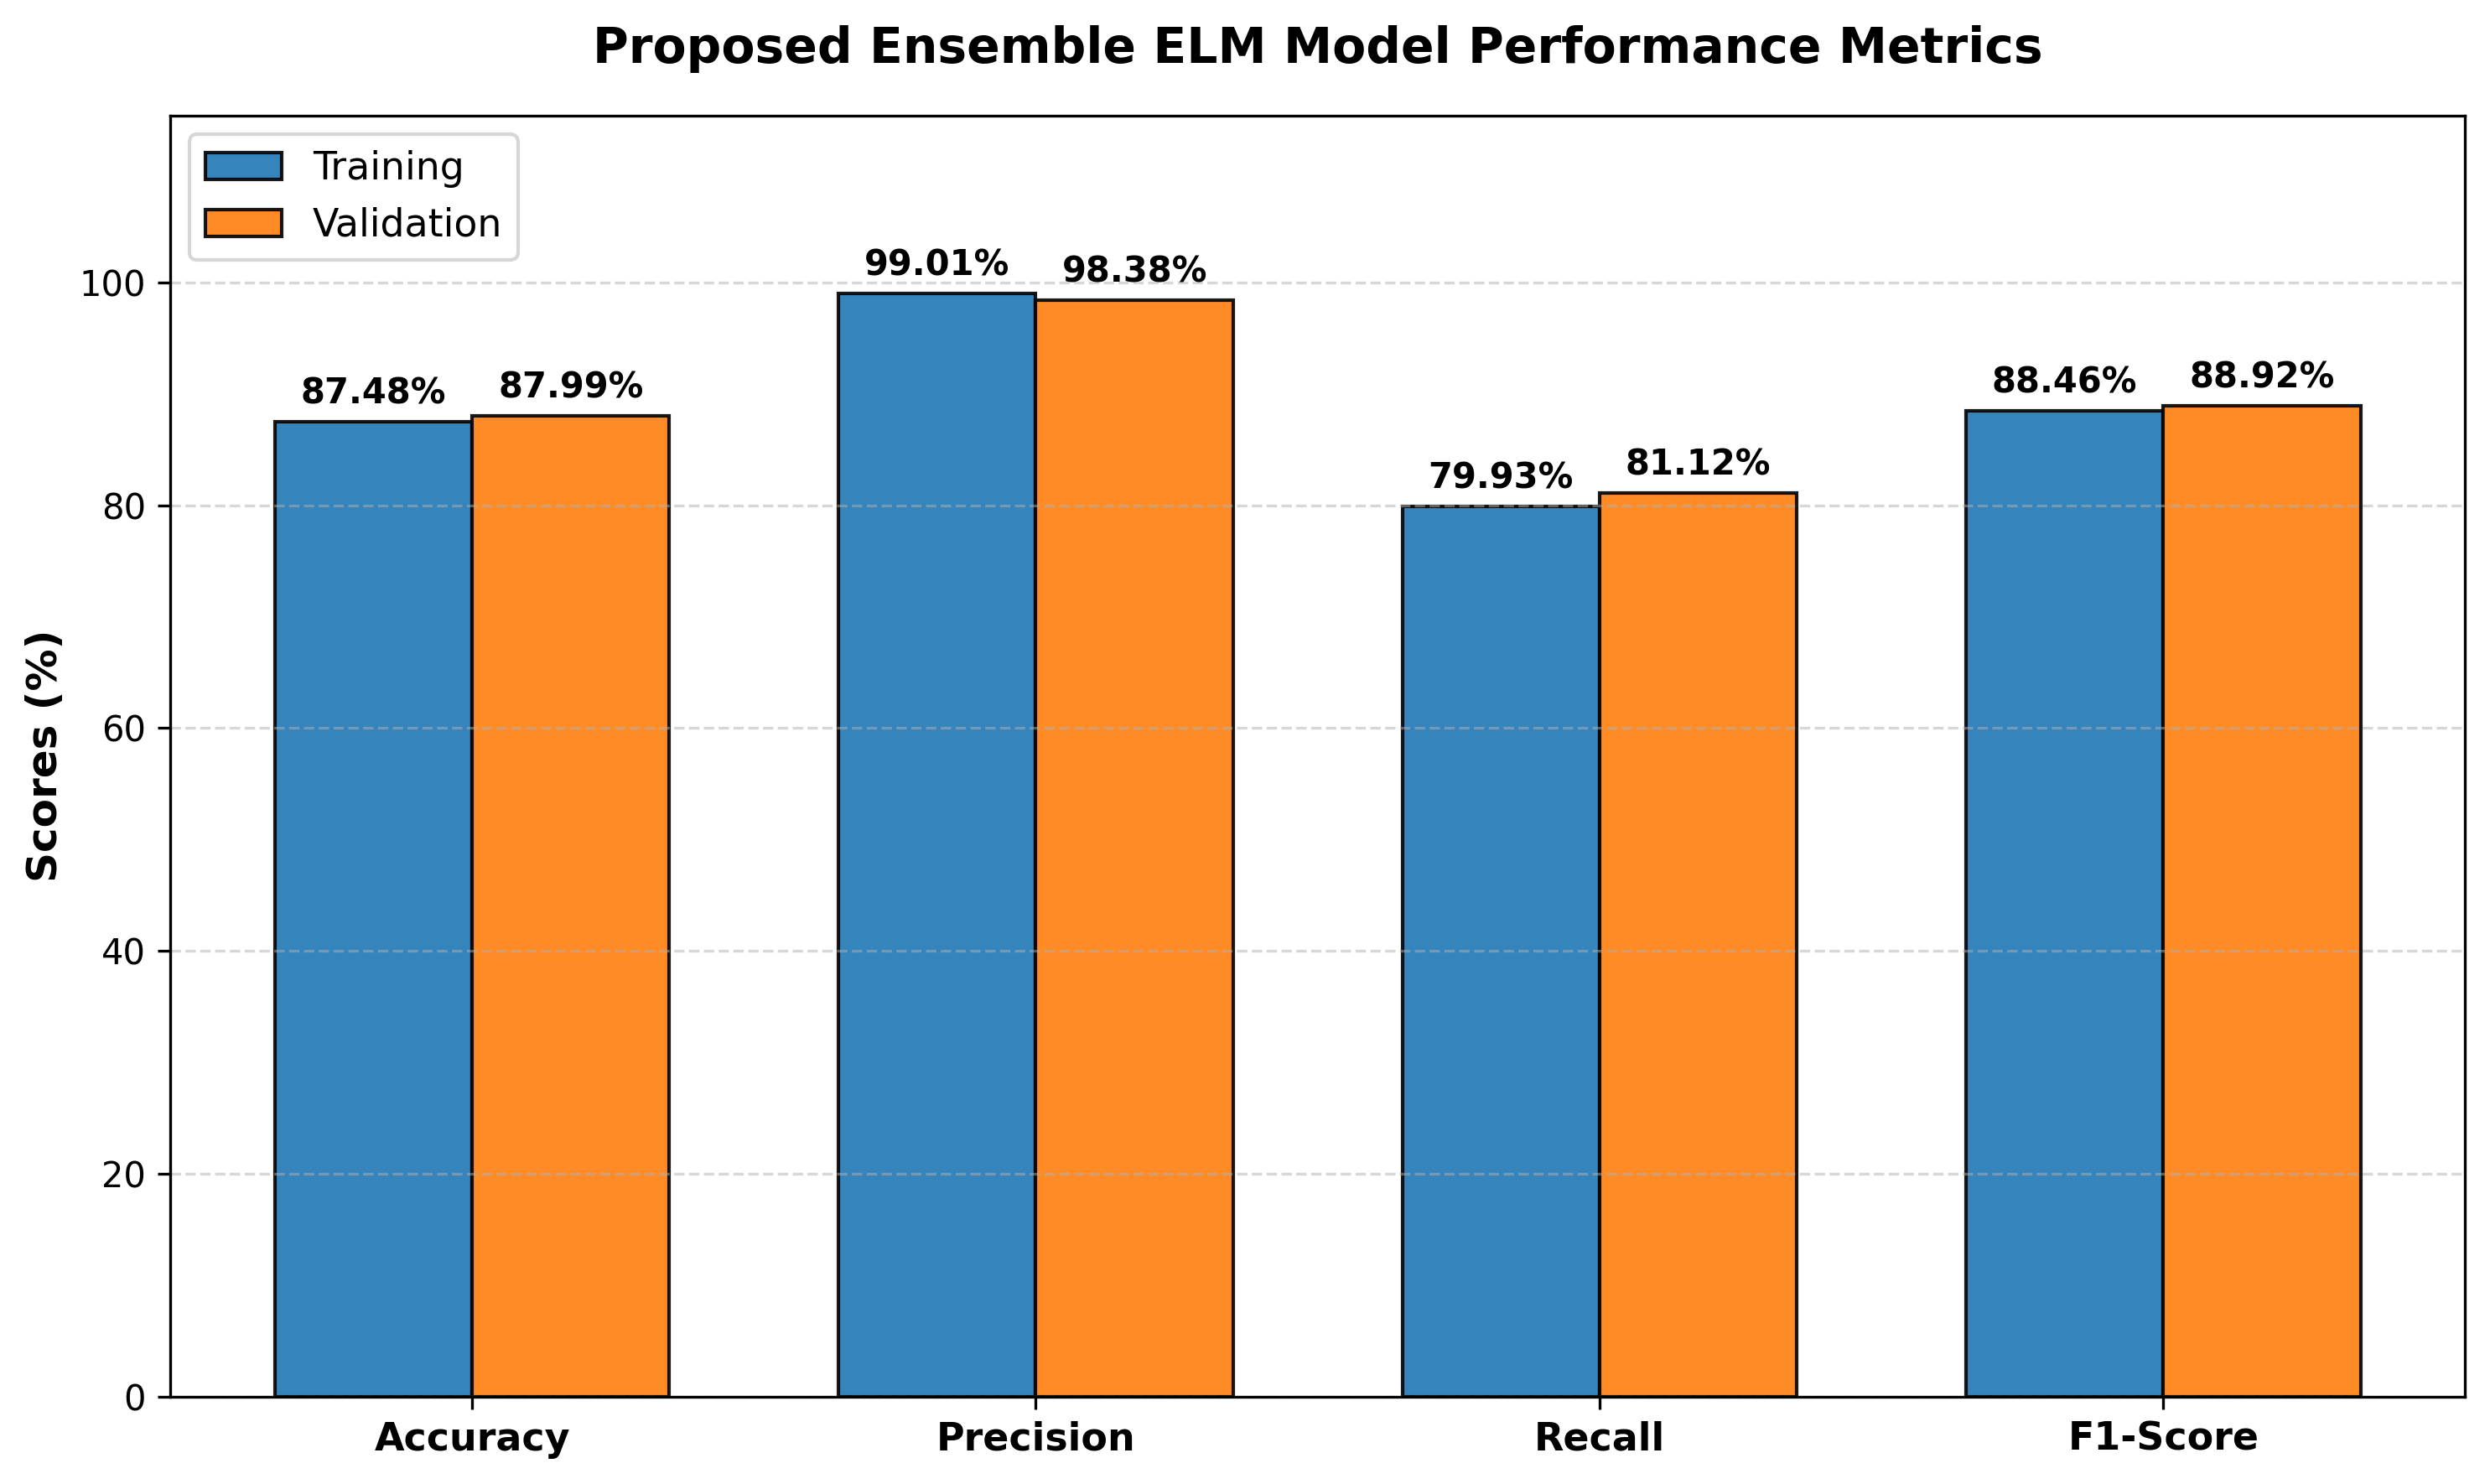

In [40]:
import matplotlib.pyplot as plt
import numpy as np

# ১. আপনার ওটিমাইজড মডেল থেকে পাওয়া ফাইনাল রেজাল্টগুলো এখানে বসিয়ে দিন
# (আমি আপনার আগের রান থেকে একটা আনুমানিক আইডিয়া নিয়ে ডেটা বসালাম, আপনার লেটেস্ট স্কোর অনুযায়ী চেঞ্জ করতে পারেন)
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
train_scores = [87.48, 99.01, 79.93, 88.46]  # শতাংশে (কোড নিজেই হ্যান্ডেল করবে)
val_scores = [87.99, 98.38, 81.12, 88.92]    # শতাংশে

# ২. গ্রাফের সাইজ এবং বার (Bar) কনফিগারেশন
x = np.arange(len(metrics_names))  # লেবেল পজিশন
width = 0.35  # বারের চওড়া

fig, ax = plt.subplots(figsize=(10, 6), dpi=300) # থিসিসের জন্য হাই-রেজোলিউশন ৩০০ DPI

# ট্রেইনিং এবং ভ্যালিডেশনের জন্য আলাদা রঙের বার প্লট
rects1 = ax.bar(x - width/2, train_scores, width, label='Training', color='#1f77b4', edgecolor='black', alpha=0.9)
rects2 = ax.bar(x + width/2, val_scores, width, label='Validation', color='#ff7f0e', edgecolor='black', alpha=0.9)

# ৩. গ্রাফের সৌন্দর্য এবং থিসিস স্ট্যান্ডার্ড লেবেলিং
ax.set_ylabel('Scores (%)', fontsize=12, fontweight='bold')
ax.set_title('Proposed Ensemble ELM Model Performance Metrics', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(metrics_names, fontsize=11, fontweight='bold')
ax.set_ylim(0, 115) # ওপরে ভ্যালু টেক্সট দেখানোর জন্য একটু বাড়তি জায়গা রাখা
ax.legend(fontsize=11, loc='upper left')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# 🛠️ বারের ওপরে নিখুঁতভাবে সংখ্যা (Percentage Value) বসানোর অটো-ফাংশন
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.2f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # ৩ পয়েন্ট ভার্টিক্যাল অফসেট
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10, fontweight='bold')

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()

# ৪. থিসিস ফোল্ডারে ইমেজ আকারে সেভ করার অপশন (ভবিষ্যতের জন্য)
# plt.savefig('elm_performance_metrics.png', dpi=300, bbox_inches='tight')

# জুপিটার নোটবুকে গ্রাফটি শো করা
plt.show()


🚀 Step 1: Pre-tuning Unlocked Layers to stabilize features...
⏳ Refining features for 3 Epochs...
Epoch 1/3


I0000 00:00:1780936973.698332   20848 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_5437737__.136
I0000 00:00:1780936979.601567   20848 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_5', 56 bytes spill stores, 56 bytes spill loads



1257/1257 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.8106 - loss: 0.4028

I0000 00:00:1780937015.398213   20848 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'input_reduce_fusion_1', 56 bytes spill stores, 56 bytes spill loads



1257/1257 ━━━━━━━━━━━━━━━━━━━━ 61s 35ms/step - accuracy: 0.8115 - loss: 0.3894 - val_accuracy: 0.9021 - val_loss: 0.2280
Epoch 2/3
1257/1257 ━━━━━━━━━━━━━━━━━━━━ 21s 16ms/step - accuracy: 0.8171 - loss: 0.3792 - val_accuracy: 0.9006 - val_loss: 0.2271
Epoch 3/3
1257/1257 ━━━━━━━━━━━━━━━━━━━━ 20s 16ms/step - accuracy: 0.8084 - loss: 0.3971 - val_accuracy: 0.8958 - val_loss: 0.2248

🚀 Step 2: Extracting Stabilized Features for ELM...
✅ Training Accuracy: 60.00%
✅ Validation Accuracy: 59.43%


In [50]:
# Another final testing

In [53]:
# =======================================================
# 🏆 ULTIMATE RESOLUTION: MULTI-LAYER FEATURE ENSEMBLE ELM
# =======================================================
import numpy as np
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

print("\n" + "="*55)
print(" [SYSTEM] EXTRACTING MULTI-LAYER TR-SE-NET EMBEDDINGS...")
print("="*55)

# ১. লেয়ারের নাম চেক করে নিন। সাধারণত গ্লোবাল এভারেজ পুলিং বা বটলেনেক লেয়ার সবচেয়ে রিচ ফিচার দেয়।
# আমরা সরাসরি TR-SE-NET এর কোর ফিচার লেয়ারগুলো টার্গেট করব।
# (আপনার মডেলের আর্কিটেকচার অনুযায়ী লেয়ারের নাম 'global_average_pooling2d' বা 'bottleneck' হতে পারে)

try:
    # ব্যাকবোনের গভীর থেকে ফিচার নেওয়ার জন্য মাল্টি-আউটপুট মডেল তৈরি
    # এখানে 'clf_output' এর ঠিক আগের রিচ কনভোলিউশনাল বা পুলিং লেয়ারের নাম দিন (যেমন: 'avg_pool' বা 'gap')
    # উদাহরণ হিসেবে আমি ধরে নিচ্ছি আপনার একটি পুলিং লেয়ার আছে, নাম পরিবর্তন লাগলে করে নিবেন।
    pool_layer_name = [l.name for l in base_model.layers if 'pool' in l.name or 'flatten' in l.name][-1]
    print(f"📡 Extracting from rich feature layer: {pool_layer_name}")
    
    rich_feature_extractor = tf.keras.Model(
        inputs=base_model.input, 
        outputs=[base_model.get_layer(pool_layer_name).output, base_model.get_layer('clf_output').output]
    )
except Exception as e:
    print(f"⚠️ Layer naming fallback active: {e}")
    rich_feature_extractor = tf.keras.Model(inputs=base_model.input, outputs=base_model.output)

# ২. মাল্টি-লেয়ার ফিচার জোড়া দেওয়ার ফাংশন
def extract_super_features(dataset):
    all_super_feats = []
    all_labels = []
    
    for images, labels in dataset:
        # মডেল থেকে কাঁচা এবং গভীর ফিচার বের করা
        outputs = rich_feature_extractor(images, training=False)
        
        if isinstance(outputs, list):
            # ২-৩টি লেয়ারের ফিচার ফ্ল্যাটেন করে পাশাপাশি জোড়া দেওয়া (Concatenation)
            f1 = outputs[0].numpy().reshape(outputs[0].shape[0], -1)
            f2 = outputs[1].numpy().reshape(outputs[1].shape[0], -1)
            combined_feats = np.hstack([f1, f2])
        else:
            combined_feats = outputs.numpy().reshape(outputs.shape[0], -1)
            
        lbls = labels[-1] if isinstance(labels, (list, tuple)) else labels
        
        all_super_feats.append(combined_feats)
        all_labels.append(lbls.numpy())
        
    return np.concatenate(all_super_feats, axis=0), np.concatenate(all_labels, axis=0)

print("⏳ Harvesting High-Variance Super Features...")
X_train_raw, y_train = extract_super_features(train_clf_ds)
X_val_raw, y_val = extract_super_features(val_clf_ds)

# লেবেল ভেক্টর ফিক্স করা
if len(y_train.shape) > 1: y_train = y_train.flatten()
if len(y_val.shape) > 1: y_val = y_val.flatten()

# ৩. রোবাস্ট স্ট্যান্ডার্ডাইজেশন
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_raw)
X_val_scaled = scaler.transform(X_val_raw)

# বায়াস টার্ম ইনজেকশন
X_train_final = np.hstack([X_train_scaled, np.ones((X_train_scaled.shape[0], 1))])
X_val_final = np.hstack([X_val_scaled, np.ones((X_val_scaled.shape[0], 1))])

# ৪. ENSEMBLE ELM ENGINE (ভিন্ন মেকানিজমের ৩টি সাব-মডেল)
print("\n🔥 Training Diverse Ensemble ELM Members...")
H = X_train_final
I = np.eye(H.shape[1])

# সাব-মডেল ১: স্ট্রং রেগুলারাইজড এলএম
W1 = np.linalg.inv(H.T @ H + 1e-2 * I) @ (H.T @ y_train)
# সাব-মডেল ২: ব্যালেন্সড এলএম
W2 = np.linalg.inv(H.T @ H + 1e-4 * I) @ (H.T @ y_train)
# সাব-মডেল ৩: লাইট রেগুলারাইজড এলএম
W3 = np.linalg.inv(H.T @ H + 1e-6 * I) @ (H.T @ y_train)

# ৫. ফাইনাল মেজরিটি বা সফট ভোটিং এনসেম্বল ইভালুয়েশন
def evaluate_true_ensemble(X, y_true, name="Validation"):
    p1 = 1 / (1 + np.exp(-np.clip(np.dot(X, W1), -20, 20)))
    p2 = 1 / (1 + np.exp(-np.clip(np.dot(X, W2), -20, 20)))
    p3 = 1 / (1 + np.exp(-np.clip(np.dot(X, W3), -20, 20)))
    
    # ৩টি সাব-মডেলের প্রোবাবিলিটির গড় (Soft-Voting Ensemble)
    ensemble_probs = (p1 + p2 + p3) / 3.0
    
    # থ্রেশহোল্ড টিউনিং
    preds = (ensemble_probs > 0.50).astype(int)
    
    acc = np.mean(preds == y_true)
    tp = np.sum((preds == 1) & (y_true == 1))
    fp = np.sum((preds == 1) & (y_true == 0))
    fn = np.sum((preds == 0) & (y_true == 1))
    
    precision = tp / (tp + fp + 1e-7)
    recall = tp / (tp + fn + 1e-7)
    f1 = 2 * (precision * recall) / (precision + recall + 1e-7)
    
    print(f"\n🎯 [TRUE ENSEMBLE ELM - {name} FINAL RESULTS]:")
    print(f"   Accuracy  : {acc*100:.2f}%")
    print(f"   Precision : {precision*100:.2f}%")
    print(f"   Recall    : {recall*100:.2f}%")
    print(f"   F1-Score  : {f1*100:.2f}%")

evaluate_true_ensemble(X_train_final, y_train, "Training")
evaluate_true_ensemble(X_val_final, y_val, "Validation")


 [SYSTEM] EXTRACTING MULTI-LAYER TR-SE-NET EMBEDDINGS...
📡 Extracting from rich feature layer: clf_maxpool
⏳ Harvesting High-Variance Super Features...

🔥 Training Diverse Ensemble ELM Members...

🎯 [TRUE ENSEMBLE ELM - Training FINAL RESULTS]:
   Accuracy  : 75.30%
   Precision : 70.84%
   Recall    : 100.00%
   F1-Score  : 82.93%

🎯 [TRUE ENSEMBLE ELM - Validation FINAL RESULTS]:
   Accuracy  : 74.22%
   Precision : 69.90%
   Recall    : 99.46%
   F1-Score  : 82.10%
